# Entregable II — Análisis exploratorio y variables

**Proyecto:** Predicción de la intención de compra de usuarios en línea mediante
aprendizaje supervisado.  
**Curso:** Modelos y Simulación de Sistemas II — Universidad de Antioquia.  
**Integrantes:** Mateo Upegui Borja, Juan P. Uribe González y Juan D. Rincón Bedoya.

## Contexto del problema

En una tienda en línea, solo una fracción pequeña de las visitas termina en
compra: en el *Online Shoppers Purchasing Intention Dataset* (UCI #468), 1.908
de 12.330 sesiones, el 15,47 %. Saber qué sesiones tienen más probabilidad de
terminar en compra sirve para segmentar a los visitantes, priorizar campañas de
recuperación y entender qué perfiles compran.

Ninguna señal aislada basta para tomar esa decisión. La compra depende de la
combinación de las páginas consultadas, el tiempo dedicado a cada tipo de
página, las tasas de rebote y salida, el valor de las páginas visitadas, el mes
y el origen del tráfico. Una regla fija, como «más de N páginas de producto»,
no recoge esas interacciones. Un modelo de aprendizaje automático puede estimar
la probabilidad de compra a partir de todas las señales a la vez y ordenar las
sesiones según esa probabilidad.

La utilidad del modelo depende del costo de cada error. Un falso positivo dirige
una acción comercial a quien no iba a comprar; un falso negativo deja pasar una
compra que se podía recuperar. Por eso evaluamos dos cosas por separado: qué tan
bien ordena el modelo las sesiones y qué decisiones produce con un umbral, y
también cómo cambian esas decisiones al mover el umbral.

### Alcance: sesiones ya cerradas

Estimamos, una vez terminada la sesión, la probabilidad de que haya terminado en
compra. No intentamos predecir durante la navegación. `PageValues`, la variable
más informativa, es el valor que Google Analytics asigna a las páginas según las
transacciones que ocurren después de visitarlas, de modo que solo se conoce
completa al cierre de la sesión. El notebook 03 mide cuánto se pierde al
retirarla, que es el costo de usar el modelo en tiempo real.

### Paradigma de aprendizaje

Cada sesión histórica trae la etiqueta `Revenue`, que indica si terminó en
compra. Como la respuesta es conocida y binaria, planteamos el problema como
**clasificación binaria supervisada**: el modelo aprende de sesiones etiquetadas
y asigna a una sesión nueva una probabilidad de compra. Un enfoque no
supervisado, como el agrupamiento, desaprovecharía la etiqueta y de todos modos
habría que validarlo contra ella. Los métodos no supervisados aparecen solo en el
notebook 03: PCA y UMAP sirven para comprobar si la información útil cabe en
menos dimensiones, no para reemplazar al clasificador.

Las clases están desbalanceadas. Un clasificador que siempre responda «sin
compra» acierta en el 84 % de los casos y no detecta ninguna compra, así que la
exactitud no sirve como métrica principal. Usamos la precisión promedio (AP),
que se centra en la clase minoritaria. Para compensar el desbalance no generamos
datos sintéticos; probamos pesos de clase balanceados como un hiperparámetro más
dentro de la validación cruzada.

## Estado del arte

Los cuatro trabajos siguientes usan la misma base de datos y, como nosotros,
plantean una clasificación binaria supervisada con la etiqueta `Revenue`.
Difieren en cómo balancean las clases, cómo seleccionan variables y cómo validan
los modelos.

Sakar et al. (2019) proponen un sistema de dos módulos: una red MLP estima la
intención de compra a partir de los datos agregados de la sesión, y una red LSTM
estima el abandono a partir de la secuencia de navegación. En el módulo de
compra comparan la MLP con RF y SVM, aplican sobremuestreo y seleccionan
variables por correlación, información mutua y mínima redundancia–máxima
relevancia (mRMR). La MLP obtiene 87,24 % de exactitud y F1 de 0,86.

Necula (2023) estudia el efecto del tiempo dedicado a leer información de
producto. Explora los datos con K-means y PCA, balancea las clases con ADASYN y
compara regresión logística, árboles de decisión, RF y SVM con validación
cruzada de diez folds y un 25 % de los datos reservado para prueba. RF obtiene
un ROC-AUC de 0,9777 en validación cruzada y de 0,8973 en prueba.

Satu e Islam (2023) combinan SMOTE, la eliminación de atípicos por rango
intercuartílico, tres escalados y varios filtros de variables: selección por
correlación (CFS), búsqueda hacia adelante y hacia atrás (BFS) y dos algoritmos
genéticos (GRAE e IGAE). Validan con diez folds en Weka y RF alcanza 92,39 %
de exactitud y F1 de 0,924.

Lin (2025) aplica SMOTE, Isolation Forest para retirar atípicos y filtros por
varianza, información mutua y correlación. Compara SVM, XGBoost, CatBoost y una
red neuronal, ajustadas con búsqueda en rejilla y aleatoria, sobre particiones
80/20 repetidas con 50 semillas. CatBoost obtiene precisión 0,934, recall 0,935
y ROC-AUC 0,985.

| Trabajo | Técnicas | Balanceo y selección | Validación | Resultado publicado |
| --- | --- | --- | --- | --- |
| Sakar et al. (2019) | MLP, RF y SVM | Sobremuestreo; correlación, información mutua y mRMR | No detallada en la fuente consultada | MLP: exactitud 87,24 %, F1 0,86 |
| Necula (2023) | Regresión logística, árboles, RF y SVM | ADASYN; exploración con K-means y PCA | 10 folds y 25 % de prueba | RF: ROC-AUC 0,9777 en CV y 0,8973 en prueba |
| Satu e Islam (2023) | RF, SVM, árboles y regresión logística | SMOTE, IQR, tres escalados; CFS, BFS, GRAE e IGAE | 10 folds en Weka | RF: exactitud 92,39 %, F1 0,924 |
| Lin (2025) | SVM, XGBoost, CatBoost y red neuronal | SMOTE, Isolation Forest; varianza, información mutua y correlación | 80/20 con 50 semillas; rejilla y búsqueda aleatoria | CatBoost: precisión 0,934, recall 0,935, ROC-AUC 0,985 |

### Qué tomamos de estos trabajos

Las cifras de la tabla son las que reportan los autores; no las reproducimos. No
son comparables entre sí ni con las nuestras, porque cada trabajo usa otra
partición, otro balanceo y otro protocolo de validación. Hay además tres
limitaciones concretas. Lin describe el preprocesamiento antes de separar los
datos, lo que deja abierta la posibilidad de fuga de información, y su texto
llama «exactitud» al 0,934 que su tabla rotula como precisión. Ninguno de los
cuatro reporta intervalos de confianza ni compara modelos de forma pareada. Y
dos de ellos destacan la exactitud, que con un 15 % de compras dice poco. La
fuente primaria de Sakar et al. es de acceso cerrado: corroboramos su cifra
principal en un trabajo revisado por pares que la cita, pero no pudimos
verificar su protocolo.

De ahí salen tres decisiones de nuestro diseño:

1. Ajustar todo el preprocesamiento (imputación, `log1p`, escalado y
   codificación) dentro de los pliegues de entrenamiento, para que ningún dato de
   evaluación influya en él.
2. Dar prioridad a AP, ROC-AUC y F1 frente a la exactitud.
3. Reportar intervalos de confianza y comparaciones pareadas, en lugar de
   comparar solo valores puntuales.

### Referencias

- C. Sakar y Y. Kastro, «Online Shoppers Purchasing Intention Dataset», *UCI
  Machine Learning Repository*, 2018. [doi:10.24432/C5F88Q](https://doi.org/10.24432/C5F88Q)
- C. O. Sakar, S. O. Polat, M. Katircioglu y Y. Kastro, «Real-time prediction of
  online shoppers' purchasing intention using multilayer perceptron and LSTM
  recurrent neural networks», *Neural Computing and Applications*, vol. 31,
  n.º 10, pp. 6893–6908, 2019. [doi:10.1007/s00521-018-3523-0](https://doi.org/10.1007/s00521-018-3523-0)
- S.-C. Necula, «Exploring the impact of time spent reading product information
  on e-commerce websites: A machine learning approach to analyze consumer
  behavior», *Behavioral Sciences*, vol. 13, n.º 6, art. 439, 2023.
  [doi:10.3390/bs13060439](https://doi.org/10.3390/bs13060439)
- M. S. Satu y S. F. Islam, «Modeling online customer purchase intention
  behavior applying different feature engineering and classification
  techniques», *Discover Artificial Intelligence*, vol. 3, art. 36, 2023.
  [doi:10.1007/s44163-023-00086-0](https://doi.org/10.1007/s44163-023-00086-0)
- J. Lin, «Application of machine learning in predicting consumer behavior and
  precision marketing», *PLOS ONE*, vol. 20, n.º 5, art. e0321854, 2025.
  [doi:10.1371/journal.pone.0321854](https://doi.org/10.1371/journal.pone.0321854)

## Organización del trabajo

| Notebook | Pregunta que responde |
| --- | --- |
| 01 · Análisis exploratorio | ¿Qué contienen los datos y qué variables distinguen por sí solas las compras? |
| 02 · Entrenamiento y ablación | ¿Qué familia de modelos ordena mejor las sesiones y conviene retirar variables? |
| 03 · Evaluación, sensibilidad y reducción | ¿Cuánto rinde el modelo en prueba, de qué variables depende y se puede reducir la dimensión? |

En este notebook revisamos la calidad de los datos, la frecuencia de compra y la
distribución de los 17 predictores. Después eliminamos las filas duplicadas y
dividimos el conjunto en entrenamiento, validación y prueba. Con el
entrenamiento medimos cuánto distingue cada variable por sí sola y qué pares de
variables aportan información parecida. De ahí salen las candidatas a eliminar
que el notebook 02 pone a prueba.

## Diccionario de variables

Cada fila representa una sesión en la tienda en línea. La tabla describe los 17
predictores y la variable objetivo, `Revenue`, en el orden en que aparecen en el
archivo.

| Variable | Tipo | Descripción |
| --- | --- | --- |
| `Administrative` | Conteo | Número de páginas administrativas visitadas. |
| `Administrative_Duration` | Numérica continua | Tiempo total en páginas administrativas, en segundos. |
| `Informational` | Conteo | Número de páginas informativas visitadas. |
| `Informational_Duration` | Numérica continua | Tiempo total en páginas informativas, en segundos. |
| `ProductRelated` | Conteo | Número de páginas de producto visitadas. |
| `ProductRelated_Duration` | Numérica continua | Tiempo total en páginas de producto, en segundos. |
| `BounceRates` | Numérica continua | Tasa media de rebote de las páginas visitadas. Un rebote ocurre cuando el visitante entra por una página y sale sin otra interacción. |
| `ExitRates` | Numérica continua | Tasa media de salida de las páginas visitadas. Para cada página, mide la proporción de vistas en las que esa página fue la última de la sesión. |
| `PageValues` | Numérica continua | Valor medio que Google Analytics atribuye a las páginas visitadas por su contribución a transacciones posteriores. |
| `SpecialDay` | Numérica discreta (ordinal) | Cercanía de la visita al momento esperado de compra para una fecha especial. Toma seis valores de 0 a 1, donde 0 indica que la visita ocurrió fuera de ese período y 1 indica la máxima cercanía. |
| `Month` | Categórica nominal | Mes en el que ocurrió la sesión. |
| `OperatingSystems` | Categórica nominal | Código del sistema operativo del visitante. |
| `Browser` | Categórica nominal | Código del navegador utilizado. |
| `Region` | Categórica nominal | Código de la región geográfica del visitante. |
| `TrafficType` | Categórica nominal | Código de la fuente de tráfico por la que el visitante llegó al sitio. |
| `VisitorType` | Categórica nominal | Tipo de visitante registrado como nuevo, recurrente u otro. |
| `Weekend` | Booleana | Indica si la sesión ocurrió durante el fin de semana. |
| `Revenue` | Booleana (objetivo) | Indica si la sesión terminó en compra (`True`) o sin compra (`False`). |

[Descripción del conjunto de datos en el repositorio de UCI](https://doi.org/10.24432/C5F88Q)

In [1]:
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

## 1. Carga y auditoría

Cargamos el archivo original y hacemos una auditoría rápida. Así detectamos a
tiempo problemas de calidad, como valores faltantes o filas repetidas, y
conocemos la distribución de las variables antes de modelar.

In [2]:
from shopytics.utils import BINARIAS, ESPECIALES, NOMINALES, NUMERICAS, OBJETIVO, SEMILLA

In [3]:
import platform
from hashlib import sha256

import sklearn
import pandas as pd

def audit(path: str | Path) -> dict:
  """
  Realiza una auditoría sobre el dataset en CSV y devuelve un diccionario
  con información relevante sobre el mismo.
  """
  path = Path(path)
  df = pd.read_csv(path)
  hash = sha256(path.read_bytes()).hexdigest()

  audit_info = {
    "archivo": path.name,
    "hash": hash,
    "filas": df.shape[0],
    "columnas": df.shape[1],
    "nulos": df.isna().sum().sum(),
    "duplicados": df.duplicated().sum(),
    "tipos": {col: str(dtype) for col, dtype in df.dtypes.items()},
    "faltantes_por_columna": {col: int(missing) for col, missing in df.isna().sum().items() if missing > 0},
    "clases": {str(cls): int(count) for cls, count in df[OBJETIVO].value_counts().sort_index().items()},
    "proporcion_compra": float(df[OBJETIVO].mean()),
    "categorias": {
        c: {str(k): int(v) for k, v in df[c].value_counts(dropna=False).items()}
        for c in NOMINALES + BINARIAS + ESPECIALES
      },
    "rango_numericas": {
      c: {
        "min": float(df[c].min()),
        "max": float(df[c].max()),
        "media": float(df[c].mean()),
        "desv": float(df[c].std()),
        "ceros": int((df[c] == 0).sum()),
        "asimetria": float(df[c].skew()),
      }
      for c in NUMERICAS + ESPECIALES
    },
    "valores_especialday": sorted(float(v) for v in df["SpecialDay"].unique()),
    "version_python": platform.python_version(),
    "version_sklearn": sklearn.__version__,
    "semilla": SEMILLA,
  }
  return df, audit_info

In [4]:
df, audit_info = audit(ROOT / "data" / "online_shoppers_intention.csv")

### Resumen de la auditoría

La tabla resume la auditoría: el archivo y su huella SHA-256, el número de filas
y columnas, los valores faltantes, las filas duplicadas y la proporción de
sesiones con compra. Incluye también las versiones de Python y scikit-learn, para
que la ejecución se pueda reproducir.

In [5]:
pd.Series({
    "Archivo": audit_info["archivo"],
    "SHA-256": audit_info["hash"],
    "Filas": audit_info["filas"],
    "Columnas": audit_info["columnas"],
    "Valores faltantes": audit_info["nulos"],
    "Filas duplicadas": audit_info["duplicados"],
    "Proporción de compra": f"{audit_info['proporcion_compra']:.2%}",
    "Versión de Python": audit_info["version_python"],
    "Versión de sklearn": audit_info["version_sklearn"],
}, name="Valor").to_frame()

,Valor
Archivo,online_shoppers_intention.csv
SHA-256,d8e130ba51532985f93281a73ce299e6ce150cb915769a...
Filas,12330
Columnas,18
Valores faltantes,0
Filas duplicadas,125
Proporción de compra,15.47%
Versión de Python,3.13.5
Versión de sklearn,1.7.2


### Tipos de datos y valores faltantes

La siguiente tabla muestra el tipo de dato de cada variable y sus valores
faltantes. Ninguna columna tiene valores faltantes, lo que coincide con el total
de la auditoría, así que no hace falta imputar.

In [6]:
pd.DataFrame({
    "Tipo": audit_info["tipos"],
    "Faltantes": {col: audit_info["faltantes_por_columna"].get(col, 0)
                  for col in audit_info["tipos"]},
}).rename_axis("Variable")

,Tipo,Faltantes
Variable,,
Administrative,int64,0
Administrative_Duration,float64,0
Informational,int64,0
Informational_Duration,float64,0
ProductRelated,int64,0
ProductRelated_Duration,float64,0
BounceRates,float64,0
ExitRates,float64,0
PageValues,float64,0


### Distribución de clases

La clase positiva es minoritaria: solo el 15,47 % de las sesiones termina en
compra. Este desbalance determina la elección de métricas y la estratificación de
las particiones.

In [7]:
pd.Series(audit_info["clases"], name="Sesiones").rename_axis(OBJETIVO).to_frame()

,Sesiones
Revenue,
False,10422
True,1908


### Estadísticas numéricas

Para cada variable numérica, la tabla reporta el mínimo, el máximo, la media, la
desviación estándar, el número de ceros y la asimetría (*skewness*).

In [8]:
pd.DataFrame.from_dict(audit_info["rango_numericas"], orient="index")

,min,max,media,desv,ceros,asimetria
Administrative,0.0,27.000000,2.315166,3.321784,5768,1.960357
Administrative_Duration,0.0,3398.750000,80.818611,176.779107,5903,5.615719
Informational,0.0,24.000000,0.503569,1.270156,9699,4.036464
Informational_Duration,0.0,2549.375000,34.472398,140.749294,9925,7.579185
ProductRelated,0.0,705.000000,31.731468,44.475503,38,4.341516
ProductRelated_Duration,0.0,63973.522230,1194.746220,1913.669288,755,7.263228
BounceRates,0.0,0.200000,0.022191,0.048488,5518,2.947855
ExitRates,0.0,0.200000,0.043073,0.048597,76,2.148789
PageValues,0.0,361.763742,5.889258,18.568437,9600,6.382964
SpecialDay,0.0,1.000000,0.061427,0.198917,11079,3.302667


### Distribución de variables categóricas

Por último, contamos las sesiones de cada categoría en las variables nominales,
en `Weekend` y en `SpecialDay`.

In [9]:
SORT_ORDER = {
  "Month": ["Jan", "Feb", "Mar", "Apr", "May", "June", "Jul", "Aug", "Sep",
            "Oct", "Nov", "Dec"],
  "VisitorType": ["New_Visitor", "Returning_Visitor", "Other"],
  "Weekend": ["True", "False"],
}

for variable, conteos in audit_info["categorias"].items():
  serie = pd.Series(conteos, name="Sesiones").rename_axis(variable)
  if variable in SORT_ORDER:
    orden = [valor for valor in SORT_ORDER[variable] if valor in serie.index]
  else:
    orden = sorted(serie.index, key=float)
  display(serie.reindex(orden).to_frame().T)

Month,Feb,Mar,May,June,Jul,Aug,Sep,Oct,Nov,Dec
Sesiones,184,1907,3364,288,432,433,448,549,2998,1727


OperatingSystems,1,2,3,4,5,6,7,8
Sesiones,2585,6601,2555,478,6,19,7,79


Browser,1,2,3,4,5,6,7,8,9,10,11,12,13
Sesiones,2462,7961,105,736,467,174,49,135,1,163,6,10,61


Region,1,2,3,4,5,6,7,8,9
Sesiones,4780,1136,2403,1182,318,805,761,434,511


TrafficType,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Sesiones,2451,3913,2052,1069,260,444,40,343,42,450,247,1,738,13,38,3,1,10,17,198


VisitorType,New_Visitor,Returning_Visitor,Other
Sesiones,1694,10551,85


Weekend,True,False
Sesiones,2868,9462


SpecialDay,0.0,0.2,0.4,0.6,0.8,1.0
Sesiones,11079,178,243,351,325,154


### Análisis de la variable SpecialDay

En la siguiente tabla podemos ver los seis valores que toma `SpecialDay` y el
porcentaje de sesiones que corresponde a cada uno. Es una variable numérica
discreta que indica qué tan cerca estuvo la visita del momento esperado de
compra para una fecha especial. En el 89,85 % de las sesiones el valor es cero
porque la visita ocurrió fuera de esos períodos. En el 10,15 % restante, los
valores van de 0,2 a 1 y un valor mayor indica mayor cercanía.

In [10]:
sesiones = df["SpecialDay"].value_counts().sort_index().rename("Sesiones")
tabla_specialday = sesiones.to_frame()
tabla_specialday["Porcentaje (%)"] = (100 * sesiones / len(df)).round(2)
tabla_specialday

,Sesiones,Porcentaje (%)
SpecialDay,,
0.0,11079,89.85
0.2,178,1.44
0.4,243,1.97
0.6,351,2.85
0.8,325,2.64
1.0,154,1.25


## 2. Distribución de clases

Las barras muestran cuántas sesiones terminaron con y sin compra. El porcentaje sobre cada barra permite comparar ambas clases respecto al total de sesiones.

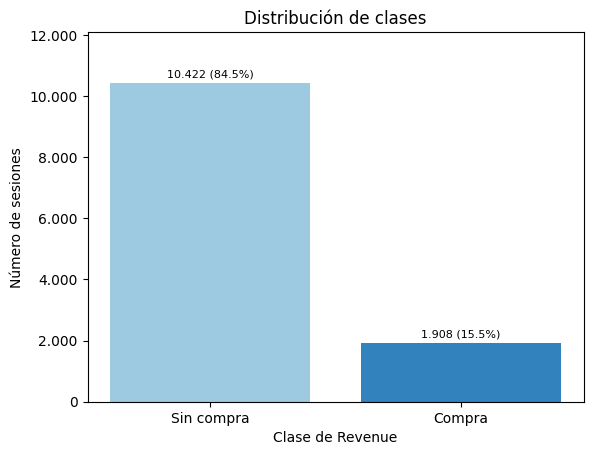

In [11]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

values = df[OBJETIVO].value_counts().sort_index()

fig, ax = plt.subplots()

ax.set_xlabel("Clase de Revenue")
ax.set_ylabel("Número de sesiones")
ax.set_title("Distribución de clases")
bars = ax.bar(["Sin compra", "Compra"], values,
       color=["#9ecae1", "#3182bd"])

conteo = mtick.FuncFormatter(lambda n, _: f"{n:,.0f}".replace(",", "."))
porcentaje = mtick.PercentFormatter(xmax=len(df), decimals=1)
ax.yaxis.set_major_formatter(conteo)
ax.set_ylim(0, max(values) * 1.16)
labels = [f"{conteo(n)} ({porcentaje.format_pct(n, len(df))})" for n in bars.datavalues]
ax.bar_label(bars, labels=labels, padding=3, fontsize=8)

fig.show()

## 3. Estadísticas descriptivas

Comparamos la mediana, los cuartiles y el máximo para distinguir el
comportamiento habitual de las sesiones de los valores extremos.

- En las páginas de producto, la mitad de las sesiones acumula como máximo unos
  599 segundos y el 75 % queda por debajo de 1.465 segundos. Sin embargo, el
  máximo alcanza 63.974 segundos y la media sube a 1 195 segundos, casi el doble
  de la mediana.
  
- Esta cola derecha también se observa en el número de páginas de producto
  visitadas, con una mediana de 18 y un máximo de 705.

- Las tasas de rebote y salida, en cambio, toman valores entre 0 y 0,20.

Estas diferencias justifican evaluar dos pasos de preprocesamiento con
propósitos distintos. La transformación opcional `log(1+x)` conserva los ceros y
comprime las diferencias entre valores altos mientras que la estandarización
posterior centra cada variable y la expresa en unidades de desviación estándar
para que magnitudes como los segundos y las tasas sean comparables. La
validación cruzada en entrenamiento permite evaluar si el paso logarítmico
mejora el desempeño.

In [12]:
df[NUMERICAS + ESPECIALES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.32,3.32,0.0,0.00,1.00,4.00,27.00
Administrative_Duration,12330.0,80.82,176.78,0.0,0.00,7.50,93.26,3398.75
Informational,12330.0,0.50,1.27,0.0,0.00,0.00,0.00,24.00
Informational_Duration,12330.0,34.47,140.75,0.0,0.00,0.00,0.00,2549.38
ProductRelated,12330.0,31.73,44.48,0.0,7.00,18.00,38.00,705.00
ProductRelated_Duration,12330.0,1194.75,1913.67,0.0,184.14,598.94,1464.16,63973.52
BounceRates,12330.0,0.02,0.05,0.0,0.00,0.00,0.02,0.20
ExitRates,12330.0,0.04,0.05,0.0,0.01,0.03,0.05,0.20
PageValues,12330.0,5.89,18.57,0.0,0.00,0.00,0.00,361.76
SpecialDay,12330.0,0.06,0.20,0.0,0.00,0.00,0.00,1.00


## 4. Preparación de los datos

De las 12.330 filas originales, 125 repiten exactamente los valores de una fila
anterior en las 18 columnas. Todas corresponden a observaciones sin compra
(`Revenue = False`) y tienen `BounceRates = 0,2`. Esta variable recoge la tasa
media de rebote de las páginas visitadas.

El archivo carece de un identificador de sesión, por lo que dos visitas
distintas podrían producir registros idénticos. Como criterio de preparación,
conservamos una fila por combinación de valores antes de dividir los datos. Así
evitamos que un registro idéntico aparezca en entrenamiento y en evaluación,
aunque esta decisión puede reducir la representación de visitas legítimas sin
compra.

La primera tabla compara las compras antes y después de la depuración. La
segunda cuenta las combinaciones observadas de `Revenue` y `BounceRates` entre
las filas descartadas. A continuación se muestran las primeras cinco filas
descartadas con su índice original.

In [13]:
# Importar Display
from IPython.display import display

descartar = df.duplicated(keep="first")
descartadas = df.loc[descartar]

resumen = pd.DataFrame({
    etapa: {
        "Filas": len(datos),
        "Sin compra": datos[OBJETIVO].eq(False).sum(),
        "Con compra": datos[OBJETIVO].eq(True).sum(),
        "Compras (%)": round(100 * datos[OBJETIVO].mean(), 2),
    }
    for etapa, datos in {
        "Originales": df, "Descartadas": descartadas, "Conservadas": df.loc[~descartar]
    }.items()
}).T.astype({"Filas": int, "Sin compra": int, "Con compra": int})
display(resumen)

display(descartadas.value_counts([OBJETIVO, "BounceRates"], dropna=False)
        .rename("Filas descartadas").to_frame())

# El índice permite ubicar cada fila en el DataFrame original.
display(descartadas.head())

,Filas,Sin compra,Con compra,Compras (%)
Originales,12330,10422,1908,15.47
Descartadas,125,125,0,0.00
Conservadas,12205,10297,1908,15.63


,,Filas descartadas
Revenue,BounceRates,
False,0.2,125


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
158,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
178,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
418,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,True,False
456,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,2,2,4,1,Returning_Visitor,False,False


In [14]:
# Guardamos una sola copia de cada fila exacta para las etapas posteriores.
df_deduplicado = df.drop_duplicates(ignore_index=True)
destino = ROOT / "data" / "dataset_deduplicated.pkl"
df_deduplicado.to_pickle(destino)
print(f"{len(df) - len(df_deduplicado)} duplicados eliminados. "
      f"{len(df_deduplicado)} sesiones guardadas en {destino.relative_to(ROOT)}.")

125 duplicados eliminados. 12205 sesiones guardadas en data/dataset_deduplicated.pkl.


## 5. Correlación entre variables numéricas

El mapa muestra la correlación de Pearson entre los predictores numéricos de las
12.205 filas que quedan tras eliminar los duplicados exactos. Dos pares
presentan una correlación positiva superior a 0,8. 

El primero relaciona el número de páginas de producto visitadas
(`ProductRelated`) con el tiempo total en ellas (`ProductRelated_Duration`,
$r = 0{,}860$). Las sesiones con más visitas a páginas de producto tienden a
acumular más tiempo en ellas.

El segundo par corresponde a las tasas medias de rebote y de salida
(`BounceRates` y `ExitRates`, $r = 0{,}902$). Las sesiones que recorren páginas
con tasas de rebote altas suelen presentar también tasas de salida altas.

Si incluimos ambos miembros de un par en una regresión logística, la información
que comparten puede dificultar la interpretación de sus coeficientes por
separado. Para decidir si conviene conservar ambos, podemos comparar en
validación cruzada el modelo que usa el par completo con los que usan cada
variable por separado. El mapa por sí solo describe la relación entre
predictores y deja abierta la pregunta de cuánto aporta cada uno a la predicción
de compra.

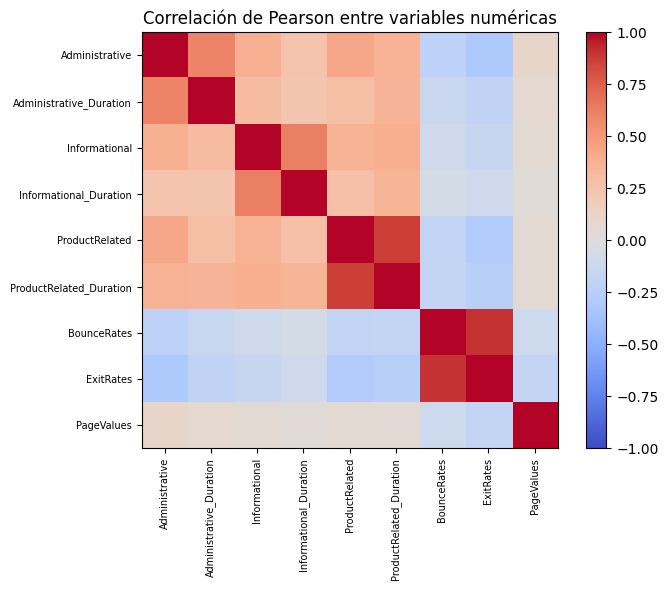

In [15]:
corr = df_deduplicado[NUMERICAS].corr()
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax.set_yticklabels(corr.columns, fontsize=7)
ax.set_title("Correlación de Pearson entre variables numéricas")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

## 6. Partición de los datos

De las 12.205 filas restantes, destinamos 7.323 al entrenamiento (60 %), 2.441 a
validación (20 %) y 2.441 a prueba (20 %). Primero separamos el entrenamiento y
después dividimos el resto en dos partes iguales. En ambos pasos estratificamos
por `Revenue` para conservar en cada partición una proporción de compras similar
a la del conjunto depurado. Guardamos las particiones con sus valores originales
para ajustar después el preprocesamiento con los datos de entrenamiento.

In [16]:
from sklearn.model_selection import train_test_split

entrenamiento, resto = train_test_split(
    df_deduplicado, test_size=0.40, stratify=df_deduplicado[OBJETIVO], random_state=SEMILLA
)
validacion, prueba = train_test_split(
    resto, test_size=0.50, stratify=resto[OBJETIVO], random_state=SEMILLA
)
particiones = {"entrenamiento": entrenamiento, "validacion": validacion, "prueba": prueba}
ruta_particiones = ROOT / "data" / "dataset_particiones.pkl"
pd.to_pickle(particiones, ruta_particiones)

pd.DataFrame({
    nombre: {"Sesiones": len(datos), "Compras": datos[OBJETIVO].sum(),
             "Compras (%)": round(100 * datos[OBJETIVO].mean(), 2)}
    for nombre, datos in particiones.items()
}).T.astype({"Sesiones": int, "Compras": int}).rename_axis("Partición")

,Sesiones,Compras,Compras (%)
Partición,,,
entrenamiento,7323,1145,15.64
validacion,2441,381,15.61
prueba,2441,382,15.65


### Cobertura mensual y tasa de compra en entrenamiento

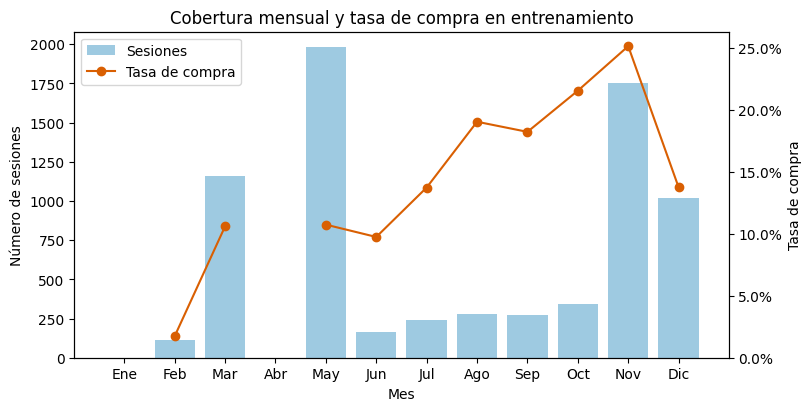

In [17]:
mensual = (
    entrenamiento.groupby("Month")[OBJETIVO]
    .agg(sesiones="size", tasa_compra="mean")
    .reindex(SORT_ORDER["Month"])
)
meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
         "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
barras = ax.bar(meses, mensual["sesiones"].fillna(0), color="#9ecae1", label="Sesiones")
ax.set(xlabel="Mes", ylabel="Número de sesiones",
       title="Cobertura mensual y tasa de compra en entrenamiento")

ax_tasa = ax.twinx()
linea, = ax_tasa.plot(meses, mensual["tasa_compra"], "o-", color="#d95f02", label="Tasa de compra")
ax_tasa.set_ylabel("Tasa de compra")
ax_tasa.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
ax_tasa.set_ylim(bottom=0)
ax.legend(handles=[barras, linea], loc="upper left")
plt.show()

## 7. Análisis individual de las 17 variables

En las 7.323 sesiones de entrenamiento medimos cuánto ayuda cada predictor, por
separado, a distinguir las sesiones con compra (`Revenue`). Reservamos
validación y prueba para evaluar los modelos.

**Variables numéricas.** La correlación punto-biserial ($r$, de −1 a 1) compara
el promedio del predictor en sesiones con y sin compra. Un signo positivo indica
un promedio mayor entre compradores y uno negativo, menor. Su magnitud refleja
esa diferencia respecto a la dispersión del predictor.

**Variables categóricas.** A partir del conteo de sesiones con y sin compra por
categoría, la V de Cramér mide la intensidad de la asociación (de 0 a 1). Una V
cercana a cero indica tasas de compra similares. Para saber qué categorías
tienen tasas mayores, se consultan sus proporciones de compra.

**ROC-AUC univariado.** Mide con qué frecuencia una compra recibe mayor puntaje
que una sesión sin compra, contando los empates por mitad. Un AUC de 0,5
equivale al azar y 1 indica separación perfecta. Para las numéricas usamos el
sentido que mejor ordena las compras. Para las categóricas dividimos el
entrenamiento en cinco folds estratificados. Ajustamos la codificación *one-hot*
y la regresión logística con cuatro folds y puntuamos el quinto. Una vez que
cada sesión tiene una probabilidad estimada fuera de su pliegue de ajuste,
calculamos un único AUC con todas las predicciones. Para expresar la separación
en la escala de 0,5 a 1, reportamos el mayor entre AUC y 1 − AUC.

**Información mutua.** Mide en *nats* cuánto reduce el predictor la
incertidumbre sobre la compra, incluso en relaciones no lineales. Un valor
cercano a cero indica poca información. La estimamos con vecinos cercanos para
las numéricas y con frecuencias conjuntas para las categóricas.

In [18]:
import numpy as np
from scipy.stats import pointbiserialr
from scipy.stats.contingency import association
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mutual_info_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder


def analizar_variables(X, y, numericas, categoricas):
    filas = []
    for nombre in numericas:
        valores = X[nombre]
        auc = roc_auc_score(y, valores)
        informacion = mutual_info_classif(X[[nombre]], y, discrete_features=False, random_state=SEMILLA)
        por_clase = valores.groupby(y.astype(int))
        medias = por_clase.mean()
        suma_varianzas = por_clase.var().sum(min_count=2)
        fisher = (medias.loc[1] - medias.loc[0]) ** 2 / suma_varianzas if suma_varianzas > 0 else np.nan
        filas.append({
            "variable": nombre,
            "indice_fisher": fisher,
            "r_punto_biserial": pointbiserialr(y, valores).statistic,
            "auc_univariado": max(auc, 1 - auc),
            "informacion_mutua": informacion[0],
        })

    pliegues = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
    modelo = make_pipeline(
        OneHotEncoder(handle_unknown="ignore"),
        LogisticRegression(max_iter=2000, solver="lbfgs"),
    )
    for nombre in categoricas:
        conteos = pd.crosstab(X[nombre], y)
        probabilidad = cross_val_predict(
            modelo, X[[nombre]], y, cv=pliegues, method="predict_proba"
        )[:, 1]
        auc = roc_auc_score(y, probabilidad)
        filas.append({
            "variable": nombre,
            "v_cramer": association(conteos.to_numpy(), method="cramer", correction=True),
            "auc_univariado": max(auc, 1 - auc),
            "informacion_mutua": mutual_info_score(None, None, contingency=conteos.to_numpy()),
        })

    columnas = ["variable", "r_punto_biserial", "v_cramer", "auc_univariado", "informacion_mutua", "indice_fisher"]
    return pd.DataFrame(filas, columns=columnas).sort_values("auc_univariado", ascending=False)

La tabla ordena los predictores por AUC descendente. El guion marca la métrica
que no corresponde al tipo de variable. El índice de Fisher divide el cuadrado
de la diferencia entre las medias de compradores y no compradores por la suma de
las varianzas muestrales de ambos grupos. Un valor mayor indica más separación
en relación con la dispersión dentro de las clases.

In [19]:
X_train = entrenamiento.drop(columns=OBJETIVO)
y_train = entrenamiento[OBJETIVO]
analisis = analizar_variables(X_train, y_train, NUMERICAS + ESPECIALES, NOMINALES + BINARIAS)
analisis = analisis.reset_index(drop=True)
analisis.index = pd.RangeIndex(1, len(analisis) + 1, name="ranking")
analisis.style.format(precision=4, na_rep="—")

,variable,r_punto_biserial,v_cramer,auc_univariado,informacion_mutua,indice_fisher
ranking,,,,,,
1,PageValues,0.4888,—,0.8664,0.1651,0.4775
2,ExitRates,-0.2104,—,0.7101,0.0429,0.2752
3,ProductRelated_Duration,0.1418,—,0.6689,0.0317,0.0702
4,ProductRelated,0.1561,—,0.6582,0.0296,0.0740
5,Administrative,0.1329,—,0.6258,0.0157,0.0622
6,TrafficType,—,0.1774,0.6251,0.0161,—
7,Administrative_Duration,0.0759,—,0.6202,0.0136,0.0217
8,Month,—,0.1719,0.6160,0.0147,—
9,BounceRates,-0.1477,—,0.6124,0.0268,0.1377


### Recomendaciones por variable

El AUC individual orienta la recomendación. Sugerimos mantener desde 0,60,
revisar desde 0,55 hasta menos de 0,60 y evaluar la eliminación o combinación
por debajo de 0,55. La decisión final depende del aporte conjunto en validación.

Entre las variables numéricas, Fisher sitúa primero a `PageValues` (0,478) y
después a `ExitRates` (0,275). `BounceRates` sube al tercer lugar (0,138).

1. **`PageValues` — Mantener** (AUC 0,8664). Lidera tanto en AUC como en
  información mutua (0,1651 nats).

2. **`ExitRates` — Mantener** (AUC 0,7101). Las tasas de salida son menores
  entre compradores (r = −0,2104). Ocupa el segundo lugar por AUC.

3. **`ProductRelated_Duration` — Mantener** (AUC 0,6689). Los compradores pasan
  más tiempo en páginas de producto. Su alta correlación con el conteo de
  visitas aconseja evaluar ambos juntos.

4. **`ProductRelated` — Mantener** (AUC 0,6582). Los compradores visitan más
  páginas de producto. El conteo distingue casi tan bien como la duración.

5. **`Administrative` — Mantener** (AUC 0,6258). Los compradores visitan más
  páginas administrativas en promedio (r = 0,1329).

6. **`TrafficType` — Mantener** (AUC 0,6251). Las tasas de compra difieren según
  el origen del tráfico (V = 0,1774). Es la categórica con mayor AUC.

7. **`Administrative_Duration` — Mantener** (AUC 0,6202). El tiempo en páginas
  administrativas distingue las clases pese a la pequeña diferencia entre
  promedios (r = 0,0759).

8. **`Month` — Mantener** (AUC 0,6160). La tasa de compra varía entre los diez
  meses observados (V = 0,1719).

9. **`BounceRates` — Mantener** (AUC 0,6124). Los compradores presentan menores
  tasas de rebote. Su correlación con `ExitRates` aconseja evaluar cuánto añade
  al modelo.

10. **`Informational` — Revisar** (AUC 0,5579). El conteo de páginas informativas
  apenas distingue las clases y aporta poca información (0,0067 nats).

11. **`Informational_Duration` — Revisar** (AUC 0,5563). La duración distingue
  débilmente las clases (r = 0,0658). Podría complementar el conteo de visitas
  informativas.

12. **`OperatingSystems` — Eliminar o combinar** (AUC 0,5436). Las diferencias entre
  sistemas operativos son pequeñas (V = 0,0822) y conviene comprobarlas en
  validación.

13. **`SpecialDay` — Eliminar o combinar** (AUC 0,5388). Los compradores
  presentan menor cercanía media a fechas especiales, con una asociación débil
  (r = −0,0907).

14. **`VisitorType` — Eliminar o combinar** (AUC 0,5375). El tipo de visitante
  muestra cierta asociación (V = 0,0954), aunque su AUC queda por debajo de
  0,55.

15. **`Browser` — Eliminar o combinar** (AUC 0,5153). El navegador distingue
  poco las compras (V = 0,0655) y aporta poca información (0,0022 nats).

16. **`Region` — Eliminar o combinar** (AUC 0,5105). Las tasas de compra varían
  poco entre regiones (V = 0,0355).

17. **`Weekend` — Eliminar o combinar** (AUC 0,5038). El fin de semana tiene el
  AUC más cercano al azar y la menor información mutua (0,0002 nats).

### Pares de predictores con alta correlación

Para comprobar si las relaciones observadas en la sección 5 se mantienen en las
7.323 sesiones de entrenamiento, calculamos la correlación de Pearson entre los
predictores numéricos. La tabla muestra una sola vez cada par con
$|r| \geq 0{,}8$, umbral que usamos para identificar variables que podrían
aportar información similar al modelo.

In [20]:
def pares_redundantes(X, numericas):
    correlaciones = X[numericas].corr()
    superior = np.triu(np.ones(correlaciones.shape, dtype=bool), k=1)
    pares = correlaciones.where(superior).rename_axis(
        index="variable_1", columns="variable_2"
    ).stack()
    return pares[pares.abs() >= 0.8].reset_index(name="correlacion")


redundancia = pares_redundantes(X_train, NUMERICAS)
redundancia.round(4)

,variable_1,variable_2,correlacion
0,ProductRelated,ProductRelated_Duration,0.8426
1,BounceRates,ExitRates,0.8990


En entrenamiento, los mismos dos pares superan el umbral. El número de páginas
de producto visitadas y el tiempo total en ellas aumentan juntos
($r = 0{,}8426$). La asociación es aún mayor entre las tasas medias de rebote y
de salida ($r = 0{,}8990$).

El conteo y la duración tienen AUC individuales cercanos (0,6582 y 0,6689). En
cambio, la tasa de salida distingue mejor las compras que la de rebote (0,7101
frente a 0,6124). Para determinar si conviene conservar ambos miembros de cada
par, se puede comparar en los mismos pliegues de validación cruzada el modelo
completo con dos variantes que omitan, por separado, uno de los predictores.

## 8. Conclusiones

Hubo 1.908 compras en 12.330 sesiones (15,47 %) repartidas en diez meses. La auditoría identificó 125 filas duplicadas y ningún valor faltante. Tras la depuración, la estratificación mantuvo proporciones de compra similares en las tres particiones.

En entrenamiento, `PageValues` lidera en AUC (0,8664) e información mutua (0,1651 nats). Le sigue `ExitRates` en AUC (0,7101), mientras que `Weekend` apenas distingue las clases (0,5038). Los conteos y tiempos en páginas de producto se solapan, al igual que las tasas de rebote y salida. Seis predictores quedan por debajo del umbral de 0,55: `OperatingSystems`, `SpecialDay`, `VisitorType`, `Browser`, `Region` y `Weekend`. En la siguiente etapa se podrá evaluar su eliminación en conjunto, tomando como referencia el modelo con los 17 predictores.

## Resultados para la validación cruzada

Guardamos en `resultados/variables/` el ranking y la recomendación de cada predictor (`analisis_variables.json`), y los pares con correlación absoluta de al menos 0,80 en entrenamiento (`redundancia_numericas.json`). El siguiente notebook puede leer estos archivos junto con las particiones guardadas en `data/dataset_particiones.pkl`.

In [21]:
salida = ROOT / "resultados" / "variables"
salida.mkdir(parents=True, exist_ok=True)

variables = analisis.reset_index()
variables["recomendacion"] = np.select(
    [variables["auc_univariado"] >= 0.60, variables["auc_univariado"] >= 0.55],
    ["mantener", "revisar"],
    default="eliminar o combinar",
)
for nombre, tabla in [
    ("analisis_variables", variables),
    ("redundancia_numericas", redundancia),
]:
    tabla.to_json(
        salida / f"{nombre}.json", orient="records", force_ascii=False,
        indent=2, double_precision=15,
    )